# Brine sand: when the near stack cannot see the sand

In `partial_stacks.ipynb` the sand was gas-filled: much softer than shale, so
even the near stack showed it brightly, and the far stacks only sharpened
the shear information. This notebook is the harder case: **the same wedge,
filled with brine**.

Brine sand and shale have almost the same P impedance (AI), so the near
stack sees only a faint reflection. They differ in S impedance (SI): brine
sand is stiffer in shear, so its reflection grows with angle. This is where
an AVO (simultaneous) inversion should change the geology, not just the
error bars.

As before, we invert the same data twice: the 5-15° stack alone, and all
three partial stacks (5-15°, 15-25°, 25-35°). The prior is unchanged: the
sand may be brine or gas (50/50) and may pinch out, so the inversion must
decide whether there is sand at all, and with what fluid.

## Step 1: the inputs

In [1]:
import sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap

from pydelivery import Inversion
from pydelivery.describe import show
from pydelivery.qc import classify_facies, facies_present, model_facies, plot_stack_qc, posterior_sections

sys.path.insert(0, ".")
from wedge_example import build_wedge, partial_stack_xml

ANGLES = [(5, 15), (15, 25), (25, 35)]
work = Path("brine_sand_data")
truth = build_wedge(work, angles=ANGLES, fluid="brine")   # same geometry and picks, brine-filled
(work / "near_only.xml").write_text(partial_stack_xml(ANGLES[:1]))
x, times = truth["x"], truth["times"]
Zp_true, Zs_true, stack_data = truth["Z_true"], truth["Zs_true"], truth["stack_data"]
thick_true = 1000 * truth["thick_true"]

inv_all = Inversion.from_files(work / "ModelDescription.xml", work / "priors.h5")
inv_near = Inversion.from_files(work / "near_only.xml", work / "priors.h5")
show(inv_all.cfg, groups=["seismic", "implied"]);

,seismic file,wavelet file,angles,offsets (m),reflector time (ms),stack velocity (m/s),noise RMS,window above/below (ms)
stack,,,,,,,,
5-15 deg,stack_5_15.h5,wavelet_5_15.h5,5-15° (rms 10.4°),-,-,-,0.01,wavelet / wavelet
15-25 deg,stack_15_25.h5,wavelet_15_25.h5,15-25° (rms 20.2°),-,-,-,0.01,wavelet / wavelet
25-35 deg,stack_25_35.h5,wavelet_25_35.h5,25-35° (rms 30.1°),-,-,-,0.01,wavelet / wavelet


Read the implied-properties table for **brine** sand: its P impedance
(6.54 M) is within 2 % of the shale's (6.65 M), so its reflection is only
−0.013 on the 5-15° stack, about the size of the noise (0.01). On the 25-35°
stack it is −0.044, more than three times larger, because the S-impedance
contrast enters with sin²θ.

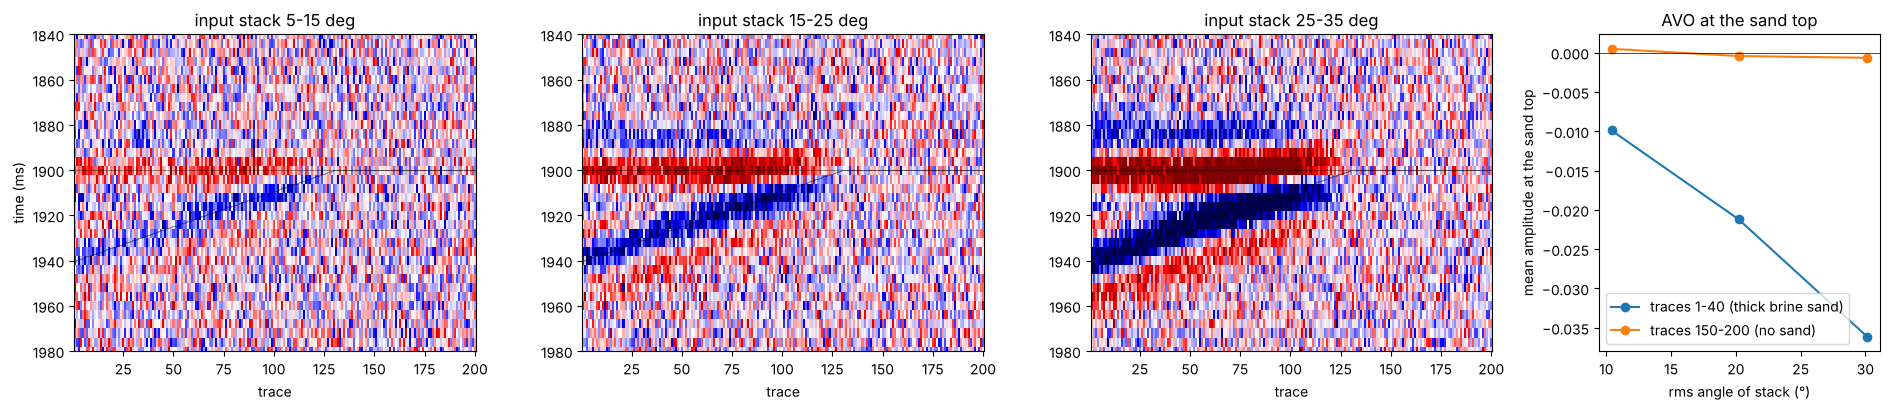

In [2]:
clip = np.percentile(np.abs(np.concatenate([d.ravel() for d in stack_data.values()])), 99.5)
ext = [0.5, len(x) + 0.5, 1000 * times[-1] + 2, 1000 * times[0] - 2]
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2), gridspec_kw=dict(width_ratios=[1, 1, 1, 0.7]))
for ax, (name, d) in zip(axes, stack_data.items()):
    ax.imshow(d.T, aspect="auto", cmap="seismic_r", vmin=-clip, vmax=clip, extent=ext, interpolation="nearest")
    ax.step(x, 1000 * truth["top_true"], "k", where="mid", lw=0.6, alpha=0.5)
    ax.step(x, 1000 * truth["base_true"], "k", where="mid", lw=0.6, alpha=0.5)
    ax.set_title(f"input stack {name}"); ax.set_xlabel("trace"); ax.set_ylim(1980, 1840)
axes[0].set_ylabel("time (ms)")
j = np.argmin(np.abs(times - 1.900))
rms_angles = [np.degrees(np.sqrt(s.angle_terms()[0])) for s in inv_all.cfg.stacks]
for lab, rng in [("traces 1-40 (thick brine sand)", slice(0, 40)), ("traces 150-200 (no sand)", slice(149, 200))]:
    amps = [stack_data[s.name][rng, j - 1:j + 2].mean() for s in inv_all.cfg.stacks]
    axes[3].plot(rms_angles, amps, "o-", label=lab)
axes[3].axhline(0, color="k", lw=0.5); axes[3].set_xlabel("rms angle of stack (°)")
axes[3].set_ylabel("mean amplitude at the sand top"); axes[3].legend(); axes[3].set_title("AVO at the sand top")
plt.tight_layout(); plt.show()

The black lines mark the true sand top and base. On the 5-15° stack the
sand is hard to pick out of the noise; on the 25-35° stack it is clear.
(The amplitude on the right is averaged over 40 traces to beat the noise;
the inversion has to work trace by trace.)

## Step 2: invert near-only and all three stacks

In [3]:
results, run_time = {}, {}
for name, inv in [("near only (5-15°)", inv_near), ("three partial stacks", inv_all)]:
    start = time.time()
    results[name] = inv.run(n_samples=500, seed=1, n_jobs=-1)
    run_time[name] = time.time() - start
    print(f"{name}: {run_time[name]:.0f} s")
NEAR, ALL = results
cfgs = {NEAR: inv_near.cfg, ALL: inv_all.cfg}
sections = {n: [posterior_sections(results[n], times, stack=k) for k in range(len(cfgs[n].stacks))]
            for n in results}

near only (5-15°): 402 s


three partial stacks: 489 s


## Step 3: is there sand, and how thick?

Top: sand thickness along the line (posterior median and 10-90 % range)
against the truth. Bottom: the probability that the sand is absent (pinched
out), brine-filled or gas-filled.

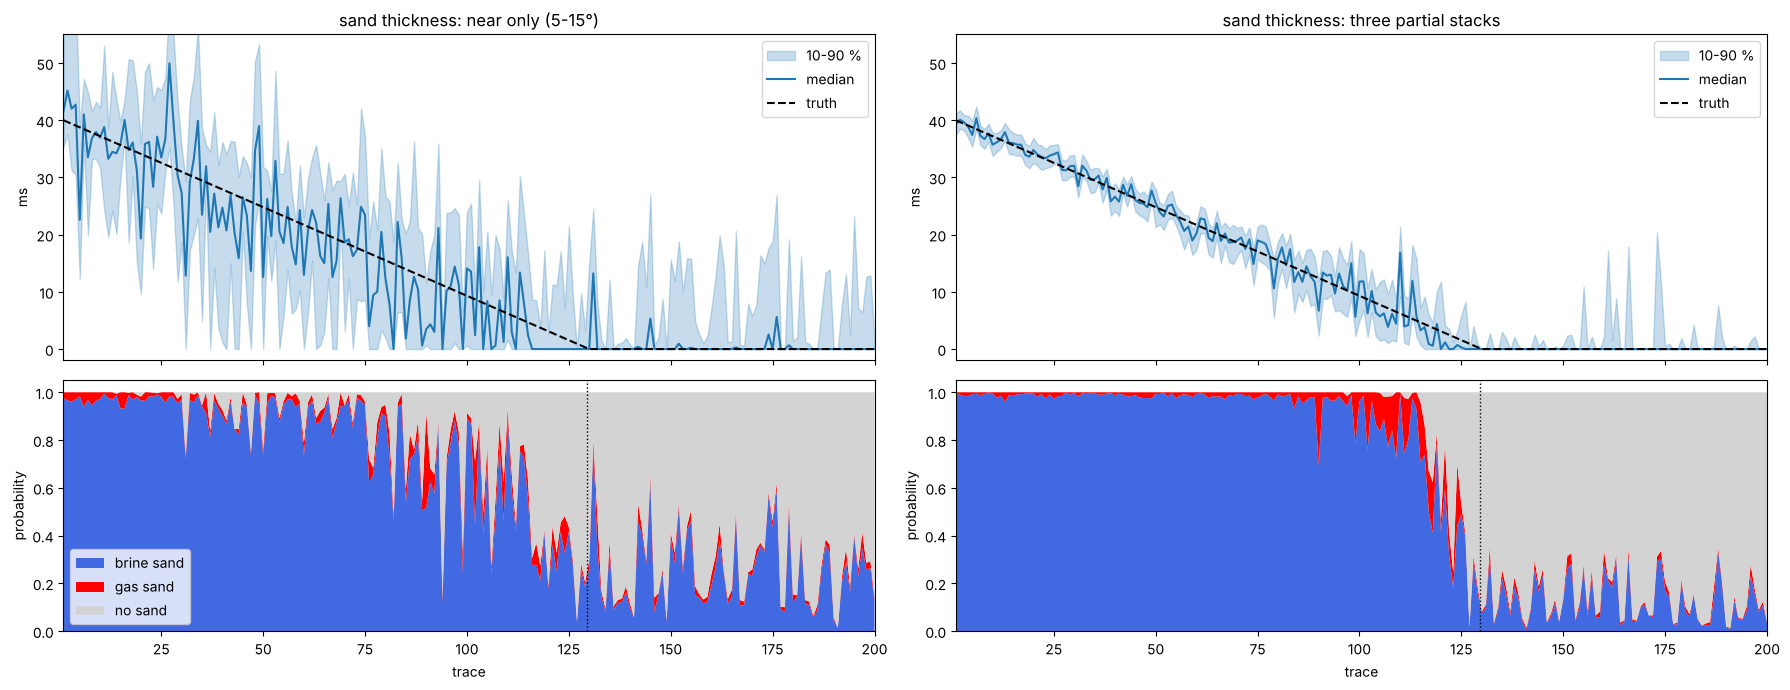

In [4]:
sand_p, thick_q = {}, {}
for n, res in results.items():
    sand_p[n] = np.array([r.fluid_probabilities()[1] for r in res])           # absent, brine, oil, lsg, gas
    th = [1000 * (r.samples["t"][:, 2] - r.samples["t"][:, 1]) for r in res]
    thick_q[n] = np.array([np.percentile(t, [10, 50, 90]) for t in th])

fig, axes = plt.subplots(2, 2, figsize=(18, 7), sharex=True, gridspec_kw=dict(height_ratios=[1.3, 1]))
for col, n in enumerate(results):
    ax = axes[0, col]
    q = thick_q[n]
    ax.fill_between(x, q[:, 0], q[:, 2], color="tab:blue", alpha=0.25, label="10-90 %")
    ax.plot(x, q[:, 1], color="tab:blue", label="median")
    ax.plot(x, thick_true, "k--", label="truth")
    ax.set_title(f"sand thickness: {n}"); ax.set_ylabel("ms"); ax.set_ylim(-2, 55); ax.legend(loc="upper right")
    p = sand_p[n]
    axes[1, col].stackplot(x, p[:, 1], p[:, 4], p[:, 0], colors=["royalblue", "red", "lightgray"],
                           labels=["brine sand", "gas sand", "no sand"])
    axes[1, col].axvline(129.5, color="k", ls=":", lw=1)
    axes[1, col].set_xlabel("trace"); axes[1, col].set_ylabel("probability"); axes[1, col].set_xlim(1, len(x))
axes[1, 0].legend(loc="lower left")
plt.tight_layout(); plt.show()

**Near only (left).** The sand is found where it is thick (traces 1-75),
but its thickness is poorly fixed: the median jumps between about 0 and 50 ms
from trace to trace and the 10-90 % range is about 21 ms wide. From trace 75
onwards the near stack gives up: the probability of no sand rises towards 50 %
while the sand is still 10-25 ms thick. Beyond the true pinch-out (dotted line)
it still gives sand a 20-40 % chance and occasional thicknesses of 10 ms or
more. The 5-15° data are consistent with all of these answers because the
brine sand barely reflects.

**Three partial stacks (right).** The thickness follows the truth all along
the wedge, with a 10-90 % range of about 6 ms, and the sand is certain down to
about trace 115, where it is about 5 ms thick. Beyond the pinch-out the chance
of sand falls to about 10-15 %.

**Fluid**: wherever either run finds sand it calls it brine, with a small gas
probability where the sand is thin. The contest here is sand against shale, not
brine against gas: gas would have been bright on every stack.

## Step 4: impedance sections, P and S

Truth, near-only estimate and three-stack estimate (posterior means), for P
impedance (top) and S impedance (bottom). The black lines are the true sand
top and base.

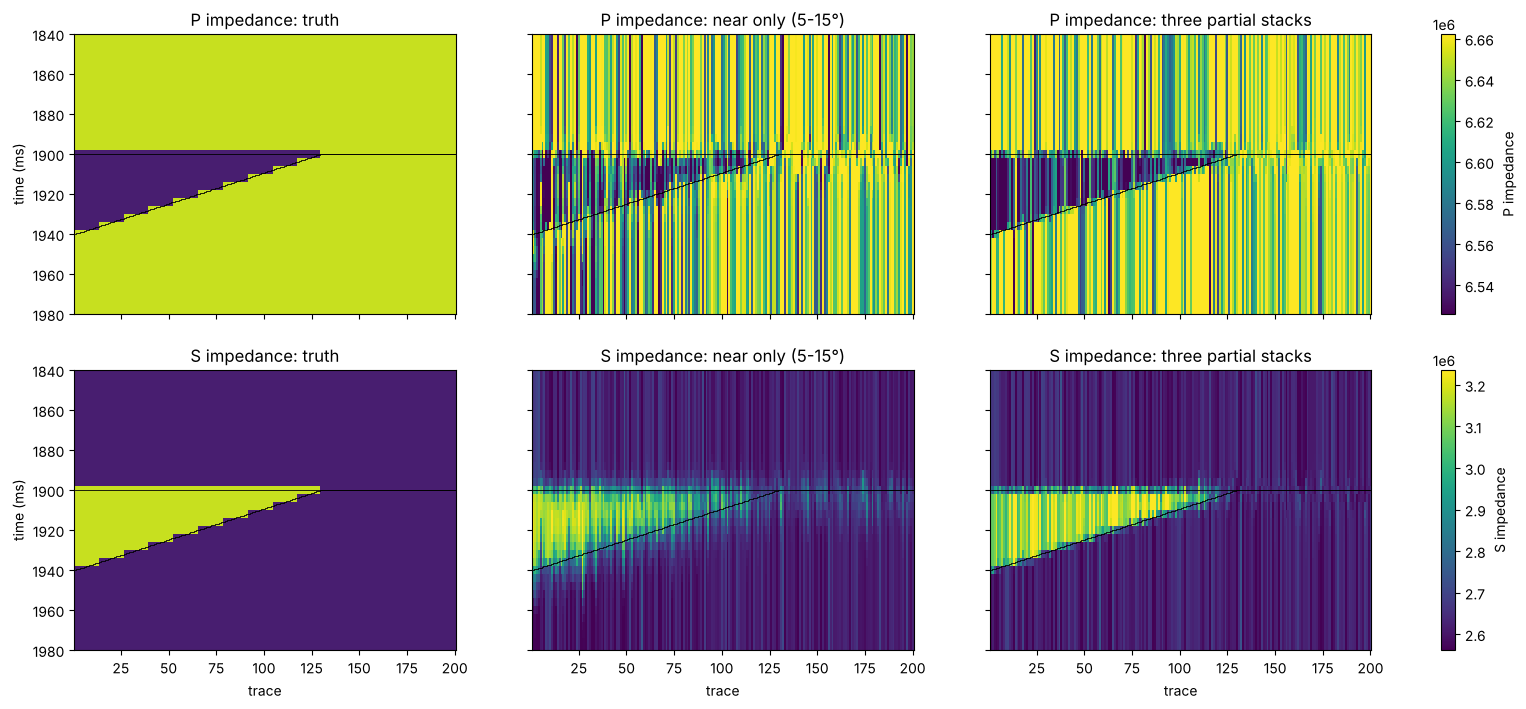

In [5]:
win = (1.84, 1.98)
fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharex=True, sharey=True)
for row, (key, true, label) in enumerate([("Zp_mean", Zp_true, "P impedance"), ("Zs_mean", Zs_true, "S impedance")]):
    lo, hi = np.percentile(true, [1, 99]); pad = 0.1 * (hi - lo); lo -= pad; hi += pad
    for ax, (title, d) in zip(axes[row], [("truth", true), (NEAR, sections[NEAR][0][key]),
                                           (ALL, sections[ALL][0][key])]):
        im = ax.imshow(d.T, aspect="auto", cmap="viridis", vmin=lo, vmax=hi, extent=ext, interpolation="nearest")
        ax.step(x, 1000 * truth["top_true"], "k", where="mid", lw=0.6)
        ax.step(x, 1000 * truth["base_true"], "k", where="mid", lw=0.6)
        ax.set_title(f"{label}: {title}")
    fig.colorbar(im, ax=axes[row].tolist(), fraction=0.02, label=label)
    axes[row, 0].set_ylabel("time (ms)")
axes[0, 0].set_ylim(1000 * win[1], 1000 * win[0])
for ax in axes[1]: ax.set_xlabel("trace")
plt.show()

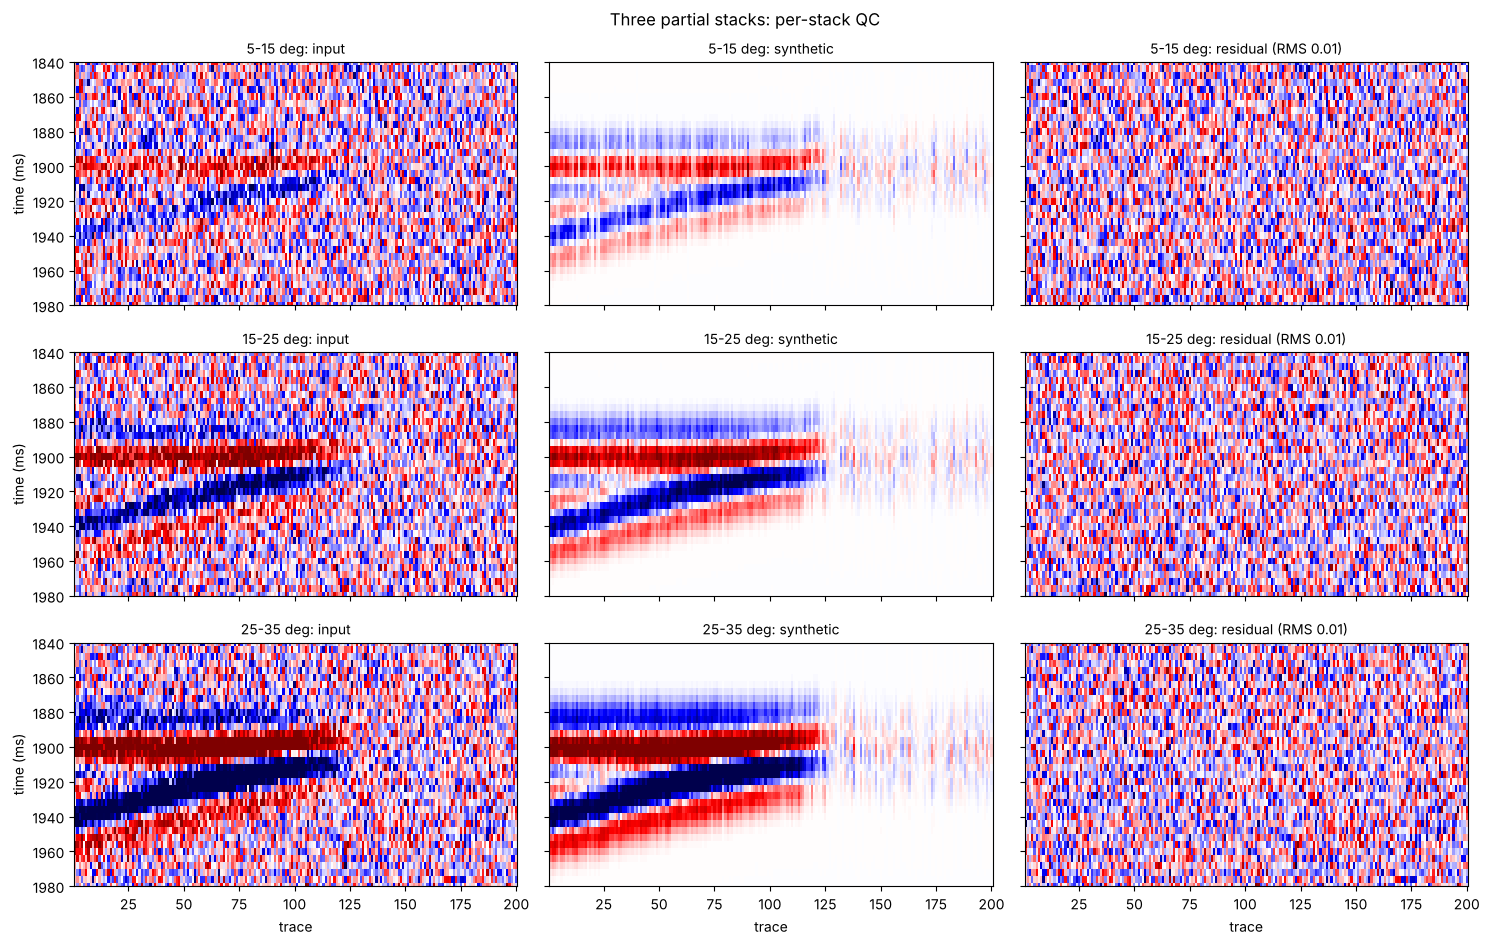

,three partial stacks,near only (5-15°)
residual RMS (noise 0.01),,
5-15 deg,0.01,0.01
15-25 deg,0.01,NaN
25-35 deg,0.01,NaN


In [6]:
synth = {s.name: sections[ALL][k]["synthetic_mean"] for k, s in enumerate(inv_all.cfg.stacks)}
fig, rms = plot_stack_qc(times, stack_data, synth, time_range=win, title="Three partial stacks: per-stack QC")
plt.show()
rms_near = np.sqrt(np.mean((stack_data["5-15 deg"] - sections[NEAR][0]["synthetic_mean"]) ** 2))
pd.DataFrame({ALL: rms, NEAR: {"5-15 deg": rms_near}}).round(4).rename_axis("residual RMS (noise 0.01)")

Both runs fit their data to the noise level (residual RMS 0.010). The
near-only run is not *wrong* in the sense of misfit: the 5-15° data simply
allow many answers, and its sections show one plausible average of them.

## Step 5: the numbers

In [7]:
has = thick_true > 0
rows = {}
for n in results:
    p, q = sand_p[n], thick_q[n]
    rows[n] = {
        "thickness error (median vs truth), sand traces, RMS ms": np.sqrt(np.mean((q[has, 1] - thick_true[has]) ** 2)),
        "thickness 10-90 % width, sand traces, mean ms": np.mean(q[has, 2] - q[has, 0]),
        "P(sand present), traces 1-100 (thick)": 1 - p[:100, 0].mean(),
        "P(sand present), traces 101-129 (thin)": 1 - p[100:129, 0].mean(),
        "P(sand present), traces 130-200 (truly absent)": 1 - p[129:, 0].mean(),
        "P(brine | sand present), traces 1-100": (p[:100, 1] / (1 - p[:100, 0])).mean(),
        "run time (s)": run_time[n],
    }
table = pd.DataFrame(rows)
table.style.format("{:.3g}")

,near only (5-15°),three partial stacks
"thickness error (median vs truth), sand traces, RMS ms",6.39,2.02
"thickness 10-90 % width, sand traces, mean ms",21.3,5.67
"P(sand present), traces 1-100 (thick)",0.91,1
"P(sand present), traces 101-129 (thin)",0.511,0.756
"P(sand present), traces 130-200 (truly absent)",0.277,0.142
"P(brine | sand present), traces 1-100",0.957,0.979
run time (s),402,489


* **Thickness**: the RMS error falls from 6.4 ms to 2.0 ms and the
  uncertainty (10-90 % width) from 21 ms to 6 ms, more than three times
  better.
* **Is there sand?** In the thin part (traces 101-129), P(sand present) rises
  from 0.51 (a coin toss) to 0.76. Where there is truly no sand (traces
  130-200), false sand falls from 0.28 to 0.14. That remainder is the prior:
  the picks put a layer there and a sand only a few ms thick is invisible on
  every stack, so the data can neither confirm nor rule it out.
* **Cost**: about 1.2× the run time.

In the impedance sections (Step 4), the P-impedance panels are striped in
both runs. That is expected: the colour scale spans only ±2 % (brine sand and
shale differ by 1.7 % in AI), so the trace-to-trace prior jitter seen in the
gas wedge fills the whole scale. The **S-impedance** panels are where the
difference shows: with three stacks the stiff brine sand fills the wedge with
the right shape and a sharp base; with the near stack alone it is a blurred
smear without a clear base.

## Step 6: AI-SI cross-plot and K-means facies

The facies in the truth are shale and brine sand. We classify the
posterior-mean AI and SI of each run into those two clusters with K-means
(clusters named by the nearest facies, as in the other notebooks). We also
print which facies the automatic rule of `lateral_continuity.ipynb` would
have picked from each run (a sand facies counts if it is more likely than
not at no fewer than 5 % of the traces).

facies the automatic rule picks from near only (5-15°): ['shale', 'sand + brine']
facies the automatic rule picks from three partial stacks: ['shale', 'sand + brine']


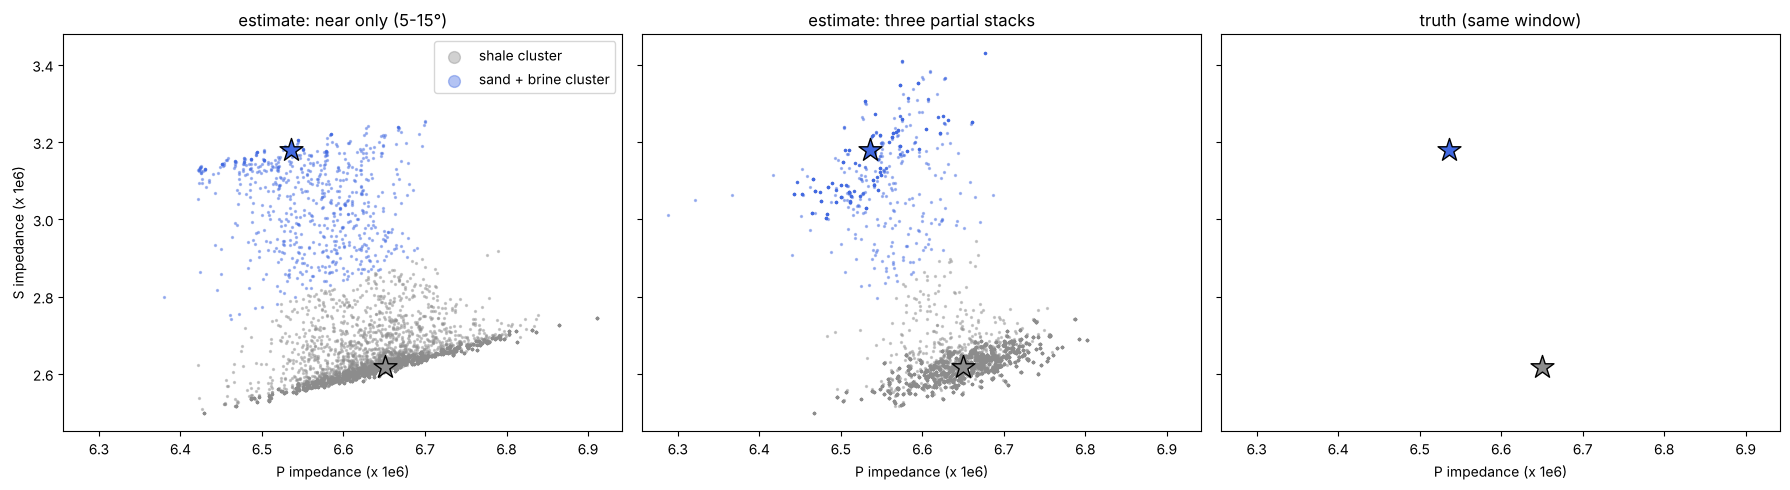

In [8]:
facies = model_facies(inv_all.cfg)
names = [f["name"] for f in facies]
SHALE, BRINE = names.index("shale"), names.index("sand + brine")
w = (times >= win[0]) & (times <= win[1])
tw = times[w]
true_lab = np.where((tw[None, :] >= truth["top_true"][:, None]) & (tw[None, :] < truth["base_true"][:, None]),
                    BRINE, SHALE)
for n in results:
    print(f"facies the automatic rule picks from {n}:", [f["name"] for f in facies_present(results[n], facies, layer=1)])
use = [facies[SHALE], facies[BRINE]]
km = {}
for n in results:
    sec = sections[n][0]
    lab, centres, nearest = classify_facies(sec["Zp_mean"][:, w], sec["Zs_mean"][:, w], use)
    km[n] = dict(lab=np.array([facies.index(f) for f in use])[lab], Zp=sec["Zp_mean"][:, w], Zs=sec["Zs_mean"][:, w])

colour = {SHALE: "0.55", BRINE: "royalblue"}
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, (n, v) in zip(axes, km.items()):
    for f_idx in np.unique(v["lab"]):
        m = v["lab"] == f_idx
        ax.scatter(v["Zp"][m] / 1e6, v["Zs"][m] / 1e6, s=2, alpha=0.4, color=colour[f_idx], label=f"{names[f_idx]} cluster")
    ax.set_title(f"estimate: {n}")
axes[2].scatter(Zp_true[:, w].ravel() / 1e6, Zs_true[:, w].ravel() / 1e6, s=20,
                c=np.where(true_lab.ravel() == BRINE, "royalblue", "0.55"))
axes[2].set_title("truth (same window)")
for ax in axes:
    for f in use:
        ax.scatter(f["Zp"] / 1e6, f["Zs"] / 1e6, marker="*", s=300, color=colour[names.index(f["name"])],
                   edgecolor="k", zorder=5)
    ax.set_xlabel("P impedance (x 1e6)")
axes[0].set_ylabel("S impedance (x 1e6)"); axes[0].legend(markerscale=6); plt.tight_layout(); plt.show()

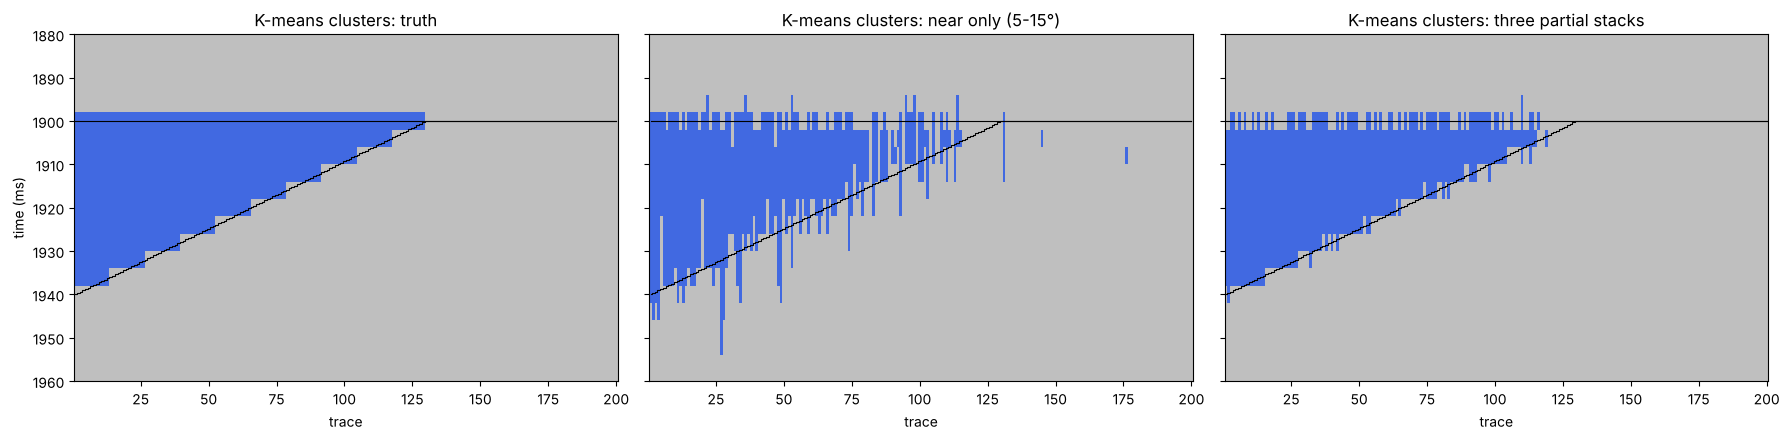

,near only (5-15°),three partial stacks
accuracy vs truth,0.971,0.987
true shale called brine sand,0.013,0.003
true brine sand found,0.831,0.896


In [9]:
cmap = ListedColormap(["0.75", "royalblue"])
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
show_lab = {"truth": np.where(true_lab == BRINE, 1, 0)} | {n: np.where(v["lab"] == BRINE, 1, 0) for n, v in km.items()}
for ax, (n, lab) in zip(axes, show_lab.items()):
    ax.imshow(lab.T, cmap=cmap, vmin=0, vmax=1, aspect="auto", interpolation="nearest",
              extent=[0.5, len(x) + 0.5, 1000 * tw[-1] + 2, 1000 * tw[0] - 2])
    ax.step(x, 1000 * truth["top_true"], "k", where="mid", lw=0.8)
    ax.step(x, 1000 * truth["base_true"], "k", where="mid", lw=0.8)
    ax.set_ylim(1960, 1880); ax.set_title(f"K-means clusters: {n}"); ax.set_xlabel("trace")
axes[0].set_ylabel("time (ms)"); plt.tight_layout(); plt.show()

def scores(lab):
    return {"accuracy vs truth": (lab == true_lab).mean(),
            "true shale called brine sand": (lab[true_lab == SHALE] != SHALE).mean(),
            "true brine sand found": (lab[true_lab == BRINE] == BRINE).mean()}
pd.DataFrame({n: scores(v["lab"]) for n, v in km.items()}).style.format("{:.3f}")

**Cross-plots.** Near only, the shale points lie along the rock-physics
trend line, and the brine-sand points spread vertically between the two
facies. The near stack fixes AI, which is the same for both facies, so it
cannot tell how much of each trace is sand. With three stacks, shale forms a
compact cloud around its star, separated in SI from the brine-sand points.

**Facies sections.** Near only, the brine-sand cluster (blue) is in the right
place at the top of the wedge, but its base is ragged and spills well below
the true base in places; it fades out near trace 115 and adds two false
patches beyond the pinch-out. With three stacks the blue fills the wedge
almost exactly, down to about trace 120 (about 4 ms thick).

**Scores.** Of the true brine-sand samples, 90 % are found with three stacks
against 83 % with the near stack alone, and shale wrongly called sand drops
from 1.3 % to 0.3 %. Overall accuracy changes less (97.1 % → 98.7 %), because
most samples are shale and both runs get those right.

## Summary

* A brine sand with the same P impedance as shale is close to invisible on a
  near stack (reflection about −0.013, noise 0.01). Near-only Delivery still
  finds the thick part, but the thickness is uncertain by ±10 ms, the thin
  edge is a coin toss and there is false sand beyond the pinch-out.
* Partial stacks to 35° see the sand through its S-impedance contrast
  (reflection −0.044 at 25-35°). Thickness error falls threefold, the wedge
  is mapped almost to its tip, and AI-SI facies classification follows the
  true geometry.
* Compared with the gas wedge (`partial_stacks.ipynb`), where the far stacks
  mainly tightened vp/vs, this is the case where they change the geological
  answer: whether there is sand and how much.